# Architecture 3 — Encoder–decoder Transformer with a copy (pointer) mechanism

Section 7.3 category: **"Encoder-decoder Transformer."**

**The idea.** The task has two clearly different parts: a **given** 512-word prompt and a 128-word **continuation**. An encoder–decoder gives each part its own stack:

- the **encoder** reads the prompt with **two-way attention** (every prompt token sees the whole prompt) and produces a representation of it;
- the **decoder** writes the continuation left to right; in every layer it can look at the encoder's representation through **cross-attention**;
- **copy mechanism:** at every step the decoder can also **copy a token straight from the prompt**, mixed with normal generation by a learned gate.

**Starting point and our changes.** The base is the original Transformer (Vaswani et al. 2017); the copy mechanism comes from pointer-generator networks (See et al. 2017), which were built for exactly this setting (copying from an encoder's input). Our own decisions:

1. **Modern blocks inside the encoder–decoder:** RoPE, RMSNorm, SwiGLU (instead of the original sinusoidal positions, LayerNorm, ReLU).
2. **Copy mechanism ported from our decoder (architecture 1)**, where the ablation showed −0.356 validation loss — here it copies from the encoder's view of the prompt.
3. **Task-matched split:** each training chunk is cut into prompt (encoder, 384–1024 tokens — the range of real test prompts) and continuation (decoder), as in B.
4. **Shared token embedding** for encoder, decoder and output layer (one 20.5M table instead of three).
5. **Continuous positions:** decoder positions continue where the prompt ends (P, P+1, …), so RoPE sees the continuation as following the prompt — just like in the decoder-only models.

**Size:** 4 encoder + 5 decoder layers (the decoder gets more depth because it writes the text), width 640 → ~73M parameters (A: 70M). Same 200M tokens, same chunks and order as A, B and architecture 1.

**Comparable numbers:** the validation metric (loss on the 768 tokens after a fixed 768-token prompt) predicts exactly the same tokens as B's validation metric, so **B and this model can be compared directly**; all models are compared on local BERTScore.

**Rules followed:** progress bars · checkpoints + resume · load instead of retrain · every result cached. `SMOKE_TEST = True` first (≈10 min), then the real run.


## 0. Setup and configuration


In [1]:
import os, sys, json, math, time, re, unicodedata, random, zipfile, subprocess
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm
from tokenizers import Tokenizer

SMOKE_TEST = False          # True = quick pipeline test. Set False for the real run.
USE_COPY   = True          # copy (pointer) mechanism from the prompt
ABLATION   = False         # True = 40M-token run, training + validation only (optional ablation)

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / ".gitignore").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Project root with .gitignore not found")
    PROJECT_ROOT = PROJECT_ROOT.parent

CFG = dict(
    arch="D_encdec", use_copy=USE_COPY, copy_dim=128,
    # model
    vocab_size=32_000, d_model=640, n_heads=10, n_enc_layers=4, n_dec_layers=5, mlp_hidden=1728, max_seq_len=1536,
    # prompt / continuation split
    prefix_min=384, prefix_max=1024, val_prefix=768,
    # data (shared by all architectures)
    train_tokens=200_000_000, mix={"sc": 0.7, "tribunals": 0.3}, eval_chunks=256,
    # optimisation
    micro_batch=2, grad_accum=5, lr=3e-4, min_lr=3e-5, warmup_steps=300,
    weight_decay=0.1, grad_clip=1.0, betas=(0.9, 0.95),
    # bookkeeping
    log_every=50, eval_every=500, ckpt_every=500, snapshot_every=1500, seed=42,
)
if ABLATION:
    CFG.update(train_tokens=40_000_000, eval_every=250, ckpt_every=250, snapshot_every=10**9)
if SMOKE_TEST:
    CFG.update(train_tokens=3_000_000, eval_every=50, ckpt_every=50, snapshot_every=100, eval_chunks=32)

RUN_NAME = (f"{CFG['arch']}_copy{int(USE_COPY)}_e{CFG['n_enc_layers']}d{CFG['n_dec_layers']}_{CFG['d_model']}"
            f"_sc70tr30_{CFG['train_tokens']//1_000_000}M" + ("_SMOKE" if SMOKE_TEST else ""))
RUN_DIR     = PROJECT_ROOT / "checkpoints" / "phase1" / RUN_NAME
TOKENS_DIR  = PROJECT_ROOT / "data" / "tokens_bpe32k"
PLAN_DIR    = PROJECT_ROOT / "data" / "train_plans"
EVAL_DIR    = PROJECT_ROOT / "data" / "local_eval"
TOK_PATH    = PROJECT_ROOT / "data" / "tokenizer" / "bpe32k.json"
EVAL_SCRIPT = PROJECT_ROOT / "scripts" / "evaluate_phase1.py"
EXP_LOG     = PROJECT_ROOT / "experiments" / "experiments.jsonl"
for d in (RUN_DIR, PLAN_DIR, EXP_LOG.parent):
    d.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if (device.type == "cuda" and torch.cuda.is_bf16_supported()) else torch.float32
random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
print("Run      :", RUN_NAME)
print("Run dir  :", RUN_DIR)
print("Device   :", device, "| precision:", AMP_DTYPE)

Run      : D_encdec_copy1_e4d5_640_sc70tr30_200M
Run dir  : c:\Users\Atharva\Desktop\Course Sem 1\LLM\Capstone Project\checkpoints\phase1\D_encdec_copy1_e4d5_640_sc70tr30_200M
Device   : cuda | precision: torch.bfloat16


c:\Users\Atharva\Desktop\Course Sem 1\LLM\Capstone Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Cleaning function (identical copy of `02_tokenizer` / `03_prepare_data`)

Used on every prompt before generation, so prompts look exactly like the training text.


In [2]:
SIGNATURE_RE = re.compile(r"Signature Not Verified.{0,150}?IST(\s*Reason:)?", flags=re.DOTALL)
ASCII_MAP = str.maketrans({
    "\u2018": "'", "\u2019": "'", "\u201a": "'", "\u201b": "'",
    "\u201c": '"', "\u201d": '"', "\u201e": '"', "\u201f": '"',
    "\u2013": "-", "\u2014": "-", "\u2015": "-", "\u2212": "-",
    "\u2026": "...",
    "\u00a0": " ", "\u2009": " ", "\u200b": "",
    "\u00ad": "",
    "\u20b9": "Rs.", "\u00a7": "S.", "\u2022": "-", "\u00b7": ".",
})
def clean_text(text):
    text = SIGNATURE_RE.sub(" ", text)
    text = text.translate(ASCII_MAP)
    text = unicodedata.normalize("NFKD", text)
    text = text.encode("ascii", "ignore").decode("ascii")
    return " ".join(text.split())

## 2. Tokenizer and data

Same shared training plan as A, B and architecture 1 (same 1537-token chunks, same order).

**Splitting each chunk into prompt and continuation.** For every **micro-batch** we draw one split point `P` uniformly from 384–1024 (saved to disk, so a resumed run uses the same splits). Using one `P` per micro-batch means both chunks in it have the same lengths → no padding needed.

- encoder input = tokens `0 … P−1` (the "prompt")
- decoder input = tokens `P−1 … 1535` (starts with the _last prompt token_, exactly like generation starts after the prompt)
- decoder targets = tokens `P … 1536` (every continuation token is predicted)


In [3]:
tokenizer = Tokenizer.from_file(str(TOK_PATH))
EOS_ID, PAD_ID = tokenizer.token_to_id("<|endoftext|>"), tokenizer.token_to_id("<pad>")
assert tokenizer.get_vocab_size() == CFG["vocab_size"]

CHUNK = CFG["max_seq_len"] + 1
SOURCES = list(CFG["mix"])
train_mm = {s: np.memmap(TOKENS_DIR / f"{s}_train.bin", dtype=np.uint16, mode="r") for s in SOURCES}
sc_val   = np.memmap(TOKENS_DIR / "sc_val.bin", dtype=np.uint16, mode="r")

tokens_per_step = CFG["micro_batch"] * CFG["grad_accum"] * CFG["max_seq_len"]
total_steps     = CFG["train_tokens"] // tokens_per_step
n_chunks_needed = total_steps * CFG["micro_batch"] * CFG["grad_accum"]

mix_tag = "_".join(f"{s}{int(f*100)}" for s, f in CFG["mix"].items())
PLAN_PATH = PLAN_DIR / f"plan_{mix_tag}_{CFG['train_tokens']//1_000_000}M_ctx{CFG['max_seq_len']}_seed{CFG['seed']}.npy"
if PLAN_PATH.exists():
    plan = np.load(PLAN_PATH)
    print("[cache] loaded training plan", PLAN_PATH.name)
else:
    rng = np.random.default_rng(CFG["seed"])
    parts = []
    for sid, (s, frac) in enumerate(CFG["mix"].items()):
        n_avail = len(train_mm[s]) // CHUNK
        n_take  = int(round(n_chunks_needed * frac))
        idx = rng.choice(n_avail, size=n_take, replace=False)
        parts.append(np.stack([np.full(n_take, sid), idx], axis=1))
    plan = np.concatenate(parts); rng.shuffle(plan); plan = plan[:n_chunks_needed]
    np.save(PLAN_PATH, plan)
    print("Saved training plan", PLAN_PATH.name)

SPLIT_PATH = RUN_DIR / "split_points.npy"
n_micro = total_steps * CFG["grad_accum"]
if SPLIT_PATH.exists():
    split_P = np.load(SPLIT_PATH)
else:
    split_P = np.random.default_rng(CFG["seed"] + 2).integers(CFG["prefix_min"], CFG["prefix_max"] + 1, size=n_micro)
    np.save(SPLIT_PATH, split_P)

n_val_avail = len(sc_val) // CHUNK
val_idx_small = np.linspace(0, n_val_avail - 1, CFG["eval_chunks"]).astype(int)
val_idx_full  = np.arange(n_val_avail)

def get_chunk(mm, i):
    return torch.from_numpy(mm[i * CHUNK:(i + 1) * CHUNK].astype(np.int64))

def split(batch, P):
    return batch[:, :P], batch[:, P - 1:-1], batch[:, P:]          # encoder input, decoder input, targets

def get_batch(step, accum_i):
    mb = step * CFG["grad_accum"] + accum_i
    rows = plan[mb * CFG["micro_batch"]:(mb + 1) * CFG["micro_batch"]]
    batch = torch.stack([get_chunk(train_mm[SOURCES[s]], i) for s, i in rows]).to(device, non_blocking=True)
    return split(batch, int(split_P[mb]))

print(f"Tokens per step: {tokens_per_step:,} | total steps: {total_steps:,} | chunks: {len(plan):,}")
print(f"Split points: mean prompt {split_P.mean():.0f} tokens -> mean continuation {CHUNK - split_P.mean():.0f} tokens")

[cache] loaded training plan plan_sc70_tribunals30_200M_ctx1536_seed42.npy
Tokens per step: 15,360 | total steps: 13,020 | chunks: 130,200
Split points: mean prompt 704 tokens -> mean continuation 833 tokens


## 3. The model

**Encoder block** (×4): RMSNorm → **two-way** self-attention (no mask) → residual → RMSNorm → SwiGLU → residual.
**Decoder block** (×5): RMSNorm → **causal** self-attention → residual → RMSNorm → **cross-attention** (queries from the decoder, keys/values from the encoder output) → residual → RMSNorm → SwiGLU → residual.

- **RoPE** in both self-attentions; encoder positions `0…P−1`, decoder positions `P−1…` (continuing). **No RoPE in cross-attention**: there the decoder looks up the prompt by _content_, not by distance.
- **Cross-attention keys/values are computed once per prompt** and reused at every generation step (they depend only on the encoder output).
- **Copy mechanism** (same maths as architecture 1, now over the _prompt_): copy query from the decoder's final hidden state, copy keys from the encoder's final output, softmax over prompt positions; gate g = sigmoid(w·h + b), b initialised to 2.
  `p(y) = g · p_vocab(y) + (1 − g) · Σ_j a_tj [prompt_j = y]` — trained without ever building the full 32,000-way copy distribution.
- One embedding matrix shared by encoder input, decoder input and the output layer.


In [4]:
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)).type_as(x) * self.weight

def rope_tables(head_dim, max_len, base=10000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))
    angles = torch.outer(torch.arange(max_len).float(), inv_freq)
    return angles.cos(), angles.sin()

def apply_rope(x, cos, sin):
    half = x.shape[-1] // 2
    x1, x2 = x[..., :half], x[..., half:]
    cos, sin = cos.to(x.dtype), sin.to(x.dtype)
    return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1)

class SelfAttention(nn.Module):
    def __init__(self, d, h, causal):
        super().__init__()
        self.h, self.hd, self.causal = h, d // h, causal
        self.qkv = nn.Linear(d, 3 * d, bias=False); self.proj = nn.Linear(d, d, bias=False)
    def forward(self, x, cos, sin, cache=None):
        B, T, D = x.shape
        q, k, v = (t.view(B, T, self.h, self.hd).transpose(1, 2) for t in self.qkv(x).split(D, dim=2))
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        past = 0
        if cache is not None:
            if "k" in cache:
                past = cache["k"].shape[2]
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        y = F.scaled_dot_product_attention(q, k, v, is_causal=(self.causal and past == 0 and T > 1))
        return self.proj(y.transpose(1, 2).reshape(B, T, D))

class CrossAttention(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.h, self.hd = h, d // h
        self.q = nn.Linear(d, d, bias=False); self.kv = nn.Linear(d, 2 * d, bias=False); self.proj = nn.Linear(d, d, bias=False)
    def memory(self, enc):                                       # keys/values of the prompt: computed once
        B, S, D = enc.shape
        k, v = self.kv(enc).split(D, dim=2)
        return k.view(B, S, self.h, self.hd).transpose(1, 2), v.view(B, S, self.h, self.hd).transpose(1, 2)
    def forward(self, x, mem):
        B, T, D = x.shape
        q = self.q(x).view(B, T, self.h, self.hd).transpose(1, 2)
        y = F.scaled_dot_product_attention(q, mem[0], mem[1])   # every decoder token sees the whole prompt
        return self.proj(y.transpose(1, 2).reshape(B, T, D))

class SwiGLU(nn.Module):
    def __init__(self, d, hidden):
        super().__init__()
        self.w1 = nn.Linear(d, hidden, bias=False); self.w3 = nn.Linear(d, hidden, bias=False); self.w2 = nn.Linear(hidden, d, bias=False)
    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))

class EncBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.n1, self.attn = RMSNorm(c["d_model"]), SelfAttention(c["d_model"], c["n_heads"], causal=False)
        self.n2, self.mlp  = RMSNorm(c["d_model"]), SwiGLU(c["d_model"], c["mlp_hidden"])
    def forward(self, x, cos, sin):
        x = x + self.attn(self.n1(x), cos, sin)
        return x + self.mlp(self.n2(x))

class DecBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.n1, self.attn  = RMSNorm(c["d_model"]), SelfAttention(c["d_model"], c["n_heads"], causal=True)
        self.n2, self.cross = RMSNorm(c["d_model"]), CrossAttention(c["d_model"], c["n_heads"])
        self.n3, self.mlp   = RMSNorm(c["d_model"]), SwiGLU(c["d_model"], c["mlp_hidden"])
    def forward(self, x, cos, sin, mem, cache=None):
        x = x + self.attn(self.n1(x), cos, sin, cache)
        x = x + self.cross(self.n2(x), mem)
        return x + self.mlp(self.n3(x))

class EncDecLM(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.cfg = c
        self.tok_emb = nn.Embedding(c["vocab_size"], c["d_model"])
        self.enc = nn.ModuleList(EncBlock(c) for _ in range(c["n_enc_layers"])); self.enc_norm = RMSNorm(c["d_model"])
        self.dec = nn.ModuleList(DecBlock(c) for _ in range(c["n_dec_layers"])); self.dec_norm = RMSNorm(c["d_model"])
        self.lm_head = nn.Linear(c["d_model"], c["vocab_size"], bias=False)
        self.lm_head.weight = self.tok_emb.weight                       # one shared embedding table
        if c["use_copy"]:
            self.copy_q = nn.Linear(c["d_model"], c["copy_dim"], bias=False)
            self.copy_k = nn.Linear(c["d_model"], c["copy_dim"], bias=False)
            self.copy_gate = nn.Linear(c["d_model"], 1)
        cos, sin = rope_tables(c["d_model"] // c["n_heads"], c["max_seq_len"])
        self.register_buffer("cos", cos, persistent=False); self.register_buffer("sin", sin, persistent=False)
        self.apply(lambda m: nn.init.normal_(m.weight, std=0.02) if isinstance(m, (nn.Linear, nn.Embedding)) else None)
        n_res = 2 * (c["n_enc_layers"] + c["n_dec_layers"])
        for blk in list(self.enc) + list(self.dec):
            outs = [blk.attn.proj.weight, blk.mlp.w2.weight] + ([blk.cross.proj.weight] if isinstance(blk, DecBlock) else [])
            for w in outs:
                nn.init.normal_(w, std=0.02 / math.sqrt(n_res))
        if c["use_copy"]:
            nn.init.zeros_(self.copy_gate.weight); nn.init.constant_(self.copy_gate.bias, 2.0)

    def encode(self, src):
        S = src.shape[1]
        x = self.tok_emb(src)
        for blk in self.enc:
            x = blk(x, self.cos[:S], self.sin[:S])
        return self.enc_norm(x)

    def decode(self, dec_in, mems, start_pos, caches=None):
        T = dec_in.shape[1]
        cos, sin = self.cos[start_pos:start_pos + T], self.sin[start_pos:start_pos + T]
        x = self.tok_emb(dec_in)
        for i, blk in enumerate(self.dec):
            x = blk(x, cos, sin, mems[i], None if caches is None else caches[i])
        return self.dec_norm(x)

    def forward(self, src, dec_in, y):
        enc = self.encode(src)
        mems = [blk.cross.memory(enc) for blk in self.dec]
        h = self.decode(dec_in, mems, start_pos=src.shape[1] - 1)
        logits = self.lm_head(h)
        if not self.cfg["use_copy"]:
            return F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), y.reshape(-1)), None
        q, k = self.copy_q(h).float(), self.copy_k(enc).float()
        attn = torch.softmax(q @ k.transpose(1, 2) / math.sqrt(q.shape[-1]), dim=-1)   # (B, T_dec, S_prompt)
        g = torch.sigmoid(self.copy_gate(h).float()).squeeze(-1)
        lf = logits.float()
        p_gen = torch.exp(lf.gather(-1, y.unsqueeze(-1)).squeeze(-1) - torch.logsumexp(lf, dim=-1))
        p_copy = (attn * (src.unsqueeze(1) == y.unsqueeze(2))).sum(-1)               # attention on prompt copies of the target
        p = g * p_gen + (1 - g) * p_copy
        return -torch.log(p.clamp_min(1e-9)).mean(), (1 - g).mean()

model = EncDecLM(CFG).to(device)
n_params = sum(p.numel() for p in model.parameters())
n_emb = model.tok_emb.weight.numel()
n_enc = sum(p.numel() for p in model.enc.parameters()); n_dec = sum(p.numel() for p in model.dec.parameters())
print(f"Parameters: {n_params/1e6:.2f}M (shared embeddings {n_emb/1e6:.2f}M, encoder {n_enc/1e6:.2f}M, decoder {n_dec/1e6:.2f}M)")
print("copy mechanism:", USE_COPY)
assert 50e6 <= n_params <= 300e6, "outside the 50M-300M rule"

Parameters: 73.46M (shared embeddings 20.48M, encoder 19.83M, decoder 32.98M)
copy mechanism: True


## 4. Training utilities

Learning-rate schedule, AdamW groups and checkpointing are identical to A / architecture 1.
`evaluate` uses a **fixed split at 768 tokens** (prompt) and measures the loss on the remaining 768 tokens — the same targets as B's validation metric.


In [5]:
def lr_at(step):
    if step < CFG["warmup_steps"]:
        return CFG["lr"] * (step + 1) / CFG["warmup_steps"]
    progress = (step - CFG["warmup_steps"]) / max(1, total_steps - CFG["warmup_steps"])
    return CFG["min_lr"] + 0.5 * (CFG["lr"] - CFG["min_lr"]) * (1 + math.cos(math.pi * min(progress, 1.0)))

def make_optimizer(model):
    decay    = [p for p in model.parameters() if p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.dim() < 2]
    return torch.optim.AdamW([{"params": decay, "weight_decay": CFG["weight_decay"]}, {"params": no_decay, "weight_decay": 0.0}],
                             lr=CFG["lr"], betas=CFG["betas"], fused=(device.type == "cuda"))

@torch.no_grad()
def evaluate(model, chunk_ids):
    model.eval()
    total = 0.0
    for i in chunk_ids:
        src, dec_in, y = split(get_chunk(sc_val, i).to(device).unsqueeze(0), CFG["val_prefix"])
        with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
            total += model(src, dec_in, y)[0].item()
    model.train()
    return total / len(chunk_ids)

CKPT_PATH  = RUN_DIR / "ckpt_last.pt"
FINAL_PATH = RUN_DIR / "model_final.pt"

def save_checkpoint(model, opt, next_step, history):
    tmp = CKPT_PATH.with_suffix(".tmp")
    torch.save({"model": model.state_dict(), "optim": opt.state_dict(), "step": next_step, "history": history, "cfg": CFG}, tmp)
    os.replace(tmp, CKPT_PATH)

## 5. Train — or load if already trained, or resume if interrupted

Same loop as before: 5 micro-batches → loss ÷ 5 → backward → clip → AdamW. The bar shows loss, validation loss, copy weight, speed and GPU memory.


In [6]:
history = []
if FINAL_PATH.exists():
    model.load_state_dict(torch.load(FINAL_PATH, map_location=device))
    history = json.load(open(RUN_DIR / "history.json"))
    print("Final model found -> loaded, NOT training.")
else:
    opt = make_optimizer(model)
    start_step = 0
    if CKPT_PATH.exists():
        ck = torch.load(CKPT_PATH, map_location=device)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["optim"])
        start_step, history = ck["step"], ck["history"]
        print(f"Resuming from step {start_step:,}")
    model.train()
    t0, tokens_done, running, running_copy = time.time(), 0, [], []
    bar = tqdm(range(start_step, total_steps), initial=start_step, total=total_steps, desc="training")
    for step in bar:
        for g in opt.param_groups:
            g["lr"] = lr_at(step)
        for a in range(CFG["grad_accum"]):
            src, dec_in, y = get_batch(step, a)
            with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
                loss, copy_frac = model(src, dec_in, y)
            (loss / CFG["grad_accum"]).backward()
            running.append(loss.item())
            if copy_frac is not None: running_copy.append(copy_frac.item())
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        opt.step(); opt.zero_grad(set_to_none=True)
        tokens_done += tokens_per_step
        if (step + 1) % CFG["log_every"] == 0:
            tps = tokens_done / (time.time() - t0)
            entry = {"step": step + 1, "train_loss": float(np.mean(running)), "lr": lr_at(step), "tokens_per_s": tps}
            if running_copy: entry["copy_weight"] = float(np.mean(running_copy))
            running, running_copy = [], []
            if (step + 1) % CFG["eval_every"] == 0 or step + 1 == total_steps:
                entry["val_loss"] = evaluate(model, val_idx_small)
            history.append(entry)
            mem = torch.cuda.max_memory_allocated() / 1e9 if device.type == "cuda" else 0
            bar.set_postfix(loss=f"{entry['train_loss']:.3f}", val=f"{entry.get('val_loss', float('nan')):.3f}",
                            copy=f"{entry.get('copy_weight', float('nan')):.2f}", lr=f"{entry['lr']:.1e}",
                            tok_s=f"{tps:,.0f}", mem=f"{mem:.1f}GB")
        if (step + 1) % CFG["ckpt_every"] == 0:
            save_checkpoint(model, opt, step + 1, history)
        if (step + 1) % CFG["snapshot_every"] == 0:
            torch.save(model.state_dict(), RUN_DIR / f"snap_step{step+1}.pt")
    torch.save(model.state_dict(), FINAL_PATH)
    json.dump(history, open(RUN_DIR / "history.json", "w"), indent=1)
    json.dump({**CFG, "run_name": RUN_NAME, "n_params": n_params}, open(RUN_DIR / "config.json", "w"), indent=1, default=str)
    hours = (time.time() - t0) / 3600
    json.dump({"train_hours_this_session": hours}, open(RUN_DIR / "train_time.json", "w"))
    print(f"Training finished: {hours:.2f} h this session")

training: 100%|██████████| 13020/13020 [4:14:13<00:00,  1.17s/it, copy=0.31, loss=2.828, lr=3.0e-05, mem=3.2GB, tok_s=13,105, val=2.866]      


Training finished: 4.24 h this session


## 6. Final validation (cached)

All SC validation chunks, prompt = first 768 tokens, loss on the next 768 — **directly comparable with B's continuation loss** (same targets, same context length). Also bits per character of those 768 tokens.


In [7]:
FINAL_EVAL = RUN_DIR / "final_eval.json"
if FINAL_EVAL.exists():
    final_eval = json.load(open(FINAL_EVAL)); print("[cache] loaded final validation")
else:
    model.eval()
    total_nats = total_tokens = total_chars = 0
    with torch.no_grad():
        for i in tqdm(val_idx_full, desc="final validation"):
            c = get_chunk(sc_val, i)
            src, dec_in, y = split(c.to(device).unsqueeze(0), CFG["val_prefix"])
            with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
                loss = model(src, dec_in, y)[0].item()
            total_nats += loss * y.numel(); total_tokens += y.numel()
            total_chars += len(tokenizer.decode(c[CFG["val_prefix"]:].tolist()))
    val_loss = total_nats / total_tokens
    final_eval = {"val_loss": val_loss, "metric": "continuation loss, prompt 768", "perplexity": math.exp(val_loss),
                  "bits_per_char": total_nats / total_chars / math.log(2), "val_tokens": total_tokens}
    json.dump(final_eval, open(FINAL_EVAL, "w"), indent=1)
print(f"SC validation (continuation after 768-token prompt): loss {final_eval['val_loss']:.4f} | "
      f"perplexity {final_eval['perplexity']:.2f} | bits/char {final_eval['bits_per_char']:.4f}")

final validation: 100%|██████████| 1833/1833 [00:35<00:00, 51.39it/s]

SC validation (continuation after 768-token prompt): loss 2.8740 | perplexity 17.71 | bits/char 0.8518


## 7. Loss curves

Training loss (every 50 steps) and validation loss on the fixed SC subset (every 500 steps). Saved as a PNG in the run folder.


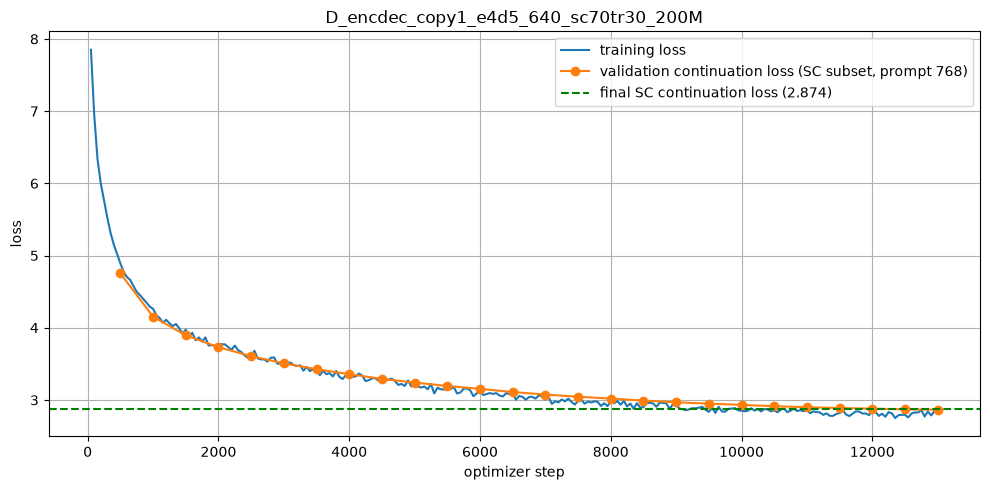

In [8]:
import matplotlib.pyplot as plt
tr = [(h["step"], h["train_loss"]) for h in history]
ev = [(h["step"], h["val_loss"]) for h in history if "val_loss" in h]
plt.figure(figsize=(10, 5))
if tr: plt.plot(*zip(*tr), label="training loss")
if ev: plt.plot(*zip(*ev), marker="o", label="validation continuation loss (SC subset, prompt 768)")
plt.axhline(final_eval["val_loss"], color="green", linestyle="--", label=f"final SC continuation loss ({final_eval['val_loss']:.3f})")
plt.xlabel("optimizer step"); plt.ylabel("loss"); plt.title(RUN_NAME); plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig(RUN_DIR / "loss_curve.png", dpi=150); plt.show()

## 7b. What does the copy mechanism copy from the prompt? (cached)

As in architecture 1, but copying is now only from the **prompt**. We split targets into "present in the prompt" (copy possible) vs "absent", and list the most-copied tokens.


In [9]:
COPY_STATS = RUN_DIR / "copy_analysis.json"
if not USE_COPY:
    print("copy mechanism off - nothing to analyse")
elif COPY_STATS.exists():
    copy_stats = json.load(open(COPY_STATS)); print("[cache] loaded copy analysis")
else:
    model.eval()
    sum_w = torch.zeros(CFG["vocab_size"], dtype=torch.float64); cnt = torch.zeros(CFG["vocab_size"], dtype=torch.float64)
    present_w, absent_w = [], []
    with torch.no_grad():
        for i in tqdm(val_idx_small, desc="copy analysis"):
            src, dec_in, y = split(get_chunk(sc_val, i).to(device).unsqueeze(0), CFG["val_prefix"])
            with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
                enc = model.encode(src)
                h = model.decode(dec_in, [blk.cross.memory(enc) for blk in model.dec], start_pos=src.shape[1] - 1)
            w = (1 - torch.sigmoid(model.copy_gate(h).float())).squeeze(-1)[0].double().cpu()
            yt = y[0].cpu()
            sum_w.index_add_(0, yt, w); cnt.index_add_(0, yt, torch.ones_like(w))
            present = (src[0].unsqueeze(0) == y[0].unsqueeze(1)).any(1).cpu()
            present_w.append(w[present]); absent_w.append(w[~present])
    pw, aw = torch.cat(present_w), torch.cat(absent_w)
    avg = sum_w / cnt.clamp_min(1)
    top = [int(t) for t in torch.argsort(avg, descending=True) if cnt[t] >= 30][:20]
    copy_stats = {"mean_copy_weight": float(torch.cat([pw, aw]).mean()),
                  "copy_weight_target_in_prompt": float(pw.mean()), "copy_weight_target_not_in_prompt": float(aw.mean()),
                  "share_targets_in_prompt": float(len(pw) / (len(pw) + len(aw))),
                  "top_copied_tokens": [(tokenizer.decode([t]), round(float(avg[t]), 3), int(cnt[t])) for t in top]}
    json.dump(copy_stats, open(COPY_STATS, "w"), indent=1)
if USE_COPY:
    print(f"mean copy weight {copy_stats['mean_copy_weight']:.3f} | target IN prompt {copy_stats['copy_weight_target_in_prompt']:.3f}"
          f" | NOT in prompt {copy_stats['copy_weight_target_not_in_prompt']:.3f} | targets present in prompt: {copy_stats['share_targets_in_prompt']:.1%}")
    for tok, wv, n in copy_stats["top_copied_tokens"]:
        print(f"  {tok!r:20s} {wv:.3f}  ({n})")

copy analysis: 100%|██████████| 256/256 [00:03<00:00, 75.41it/s]


mean copy weight 0.329 | target IN prompt 0.412 | NOT in prompt 0.176 | targets present in prompt: 64.8%
  ' PETITION'          0.818  (30)
  ' NO'                0.760  (100)
  ' DI'                0.737  (30)
  ' of'                0.736  (8300)
  '.'                  0.730  (8604)
  ' thereof'           0.684  (46)
  ' WITH'              0.668  (33)
  ' liquor'            0.644  (32)
  ' temple'            0.627  (41)
  ' the'               0.594  (14575)
  ' Suresh'            0.578  (30)
  ','                  0.558  (6142)
  ' APPEAL'            0.553  (57)
  ' 1996'              0.540  (33)
  '.,'                 0.539  (86)
  ' defendant'         0.535  (39)
  ' @'                 0.531  (66)
  ' Art'               0.517  (35)
  ' women'             0.514  (34)
  ' religion'          0.505  (42)


## 8. Generation (exactly 128 words)

1. The **encoder reads the whole prompt once** (two-way); cross-attention keys/values and copy keys of the prompt are computed **once**.
2. The decoder starts from the last prompt token at position P−1 and generates one token at a time with a **KV cache** for its own self-attention.
3. With copy on, each step mixes the vocabulary distribution with the copy distribution over the prompt tokens.
4. Same decoding rules as before: EOS/pad forbidden, repetition penalty and no-repeat n-gram over prompt + output, greedy or top-p sampling, stop after >128 words, retry with stronger anti-repetition if a loop prevents 128 words.


In [10]:
MAX_NEW_TOKENS = 400
TARGET_WORDS = 128
MAX_PROMPT_TOKENS = CFG["prefix_max"]                      # 1024: longest prompt seen in training (test max ~982)
BANNED = [EOS_ID, PAD_ID]

@torch.no_grad()
def generate_words(model, prompt_ids, temperature=0.1, top_p=0.95, rep_penalty=1.1, no_repeat_ngram=0, seed=0):
    gen = torch.Generator(device=device).manual_seed(seed)
    prompt = list(prompt_ids[-MAX_PROMPT_TOKENS:])
    seq = list(prompt)
    seen = torch.zeros(CFG["vocab_size"], dtype=torch.bool, device=device); seen[torch.tensor(seq, device=device)] = True
    ngrams = {}
    if no_repeat_ngram:
        n = no_repeat_ngram
        for j in range(len(seq) - n + 1):
            ngrams.setdefault(tuple(seq[j:j + n - 1]), set()).add(seq[j + n - 1])
    src = torch.tensor([prompt], device=device)
    with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
        enc = model.encode(src)
        mems = [blk.cross.memory(enc) for blk in model.dec]
    if USE_COPY:
        copy_keys = model.copy_k(enc[0]).float()                     # fixed: the prompt never changes
    caches = [dict() for _ in model.dec]
    pos, nxt, words = len(prompt) - 1, prompt[-1], []
    for t in range(MAX_NEW_TOKENS):
        with torch.autocast(device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE != torch.float32):
            h = model.decode(torch.tensor([[nxt]], device=device), mems, start_pos=pos, caches=caches)[0, -1]
        logits = model.lm_head(h).float()
        if USE_COPY:
            q = model.copy_q(h).float()
            a = torch.softmax(copy_keys @ q / math.sqrt(q.shape[-1]), dim=0)
            g = torch.sigmoid(model.copy_gate(h).float())
            p = g * torch.softmax(logits, dim=-1)
            p.scatter_add_(0, src[0], (1 - g) * a)
            logits = torch.log(p + 1e-12)
        logits[BANNED] = -float("inf")
        if rep_penalty != 1.0:
            pen = logits[seen]
            logits[seen] = torch.where(pen > 0, pen / rep_penalty, pen * rep_penalty)
        if no_repeat_ngram and len(seq) >= no_repeat_ngram - 1:
            banned = ngrams.get(tuple(seq[len(seq) - no_repeat_ngram + 1:]))
            if banned:
                logits[list(banned)] = -float("inf")
        if temperature == 0:
            nxt = int(torch.argmax(logits))
        else:
            probs = torch.softmax(logits / temperature, dim=-1)
            sp, si = torch.sort(probs, descending=True)
            sp[torch.cumsum(sp, dim=-1) - sp > top_p] = 0
            nxt = int(si[torch.multinomial(sp / sp.sum(), 1, generator=gen)])
        seq.append(nxt); seen[nxt] = True; pos += 1
        if no_repeat_ngram and len(seq) >= no_repeat_ngram:
            ngrams.setdefault(tuple(seq[-no_repeat_ngram:-1]), set()).add(nxt)
        if (t + 1) % 16 == 0 or t == MAX_NEW_TOKENS - 1:
            words = tokenizer.decode(seq[len(prompt):]).split()
            if len(words) > TARGET_WORDS:
                break
    return words[:TARGET_WORDS]

RETRY_CFG = {"temperature": 0.7, "top_p": 0.9, "rep_penalty": 1.2, "no_repeat_ngram": 4}

def continue_prompt(model, prompt_text, dcfg, seed):
    ids = tokenizer.encode(clean_text(prompt_text)).ids
    words = generate_words(model, ids, seed=seed, **dcfg)
    retried = False
    if len(words) < TARGET_WORDS:
        words, retried = generate_words(model, ids, seed=seed + 1, **RETRY_CFG), True
    return " ".join(words), retried

def predict_all(model, prompts, dcfg, desc, limit=None):
    model.eval()
    items = list(prompts.items())[:limit]
    preds, retries = {}, 0
    for k, (pid, rec) in enumerate(tqdm(items, desc=desc)):
        text, retried = continue_prompt(model, rec["text"], dcfg, seed=CFG["seed"] + k)
        preds[str(pid)] = {"text": text}
        retries += retried
    return preds, retries

## 9. Local evaluation (cached)

Two decoding settings on the **new** local evaluation set (200 cleaned SC validation prompts), each with a fixed seed (reproducible), scored by the **official, unchanged** `evaluate_phase1.py`.
Settings compared: the baseline's winner (T=0.1 + repetition penalty 1.1), the same **+ no-repeat 6-gram**, and **greedy + no-repeat 6-gram**.


In [11]:
SWEEP = {
    "T0.1_rep1.1_nrng6":   {"temperature": 0.1, "top_p": 0.95, "rep_penalty": 1.1, "no_repeat_ngram": 6},
    "greedy_rep1.1_nrng6": {"temperature": 0.0, "top_p": 1.0,  "rep_penalty": 1.1, "no_repeat_ngram": 6},
}
local_prompts = json.load(open(EVAL_DIR / "local_eval_prompts.json"))
if ABLATION and not SMOKE_TEST:
    SWEEP = {}                                                   # ablation runs: no generation, validation only
    print("ABLATION run: skipping local generation")
LOCAL_LIMIT = 16 if SMOKE_TEST else None
truth_path = EVAL_DIR / "local_eval_truth.json"
if LOCAL_LIMIT:                                                  # smoke test: evaluator needs matching truth ids
    keep = list(local_prompts)[:LOCAL_LIMIT]
    truth_path = RUN_DIR / "local_truth_subset.json"
    full_truth = json.load(open(EVAL_DIR / "local_eval_truth.json"))
    json.dump({k: full_truth[k] for k in keep}, open(truth_path, "w"))

def run_official_eval(pred_path, truth_path):
    env = dict(os.environ, PYTHONUTF8="1")
    r = subprocess.run([sys.executable, str(EVAL_SCRIPT), "--truth", str(truth_path), "--prediction", str(pred_path)],
                       capture_output=True, text=True, encoding="utf-8", errors="replace", env=env)
    if r.returncode != 0:
        print(r.stderr[-2000:]); return None
    scores = {}
    for line in r.stdout.splitlines():
        key, _, val = line.partition(":")
        if key.strip() in ("BERTScore F1", "ROUGE-L F1", "BLEU-4"):
            scores[key.strip()] = float(val)
    return scores

LOCAL_RESULTS = RUN_DIR / "local_eval_results.json"
local_results = json.load(open(LOCAL_RESULTS)) if LOCAL_RESULTS.exists() else {}
for name, dcfg in SWEEP.items():
    if name in local_results:
        print(f"[cache] {name}: {local_results[name]}")
        continue
    preds, retries = predict_all(model, local_prompts, dcfg, desc=f"local {name}", limit=LOCAL_LIMIT)
    pred_path = RUN_DIR / f"local_pred_{name}.json"
    json.dump(preds, open(pred_path, "w"), indent=1)
    scores = run_official_eval(pred_path, truth_path)
    local_results[name] = {**(scores or {}), "retries": retries}
    json.dump(local_results, open(LOCAL_RESULTS, "w"), indent=1)      # saved after EACH setting
    print(f"{name}: {local_results[name]}")

local T0.1_rep1.1_nrng6: 100%|██████████| 200/200 [04:12<00:00,  1.26s/it]


T0.1_rep1.1_nrng6: {'BERTScore F1': 0.823009, 'ROUGE-L F1': 0.190703, 'BLEU-4': 0.041144, 'retries': 1}


local greedy_rep1.1_nrng6: 100%|██████████| 200/200 [04:04<00:00,  1.22s/it]


greedy_rep1.1_nrng6: {'BERTScore F1': 0.821168, 'ROUGE-L F1': 0.186602, 'BLEU-4': 0.040208, 'retries': 2}


## 10. Test predictions → checks → submission.zip (cached)

Uses the decoding setting with the best local BERTScore. Checks before zipping: same IDs as `test.json`, no empty text, **every prediction exactly 128 words**.


In [12]:
from huggingface_hub import hf_hub_download
test_data = json.load(open(hf_hub_download("Exploration-Lab/CS-781-Capstone", "Phase_1_Pretraining/Test/test.json",
                                           repo_type="dataset"), encoding="utf-8"))
PRED_PATH, ZIP_PATH = RUN_DIR / "prediction.json", RUN_DIR / "submission.zip"

if ABLATION and not SMOKE_TEST:
    print("ABLATION run: no test predictions")
elif ZIP_PATH.exists():
    print("[cache] submission already exists:", ZIP_PATH)
else:
    best = max(local_results, key=lambda n: local_results[n].get("BERTScore F1", -1))
    print("Decoding:", best, SWEEP[best])
    preds, retries = predict_all(model, test_data, SWEEP[best], desc="test", limit=20 if SMOKE_TEST else None)
    wc = [len(p["text"].split()) for p in preds.values()]
    print(f"{len(preds)} predictions | words min={min(wc)} max={max(wc)} | not 128: {sum(w != 128 for w in wc)} | retries: {retries}")
    if not SMOKE_TEST:
        assert set(preds) == set(test_data), "ID mismatch with test.json"
        assert all(p["text"].strip() for p in preds.values()), "empty prediction"
        json.dump(preds, open(PRED_PATH, "w"), indent=1)
        with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as z:
            z.write(PRED_PATH, arcname="prediction.json")
        print(zipfile.ZipFile(ZIP_PATH).namelist(), "->", ZIP_PATH)

Decoding: T0.1_rep1.1_nrng6 {'temperature': 0.1, 'top_p': 0.95, 'rep_penalty': 1.1, 'no_repeat_ngram': 6}


test: 100%|██████████| 1000/1000 [29:24<00:00,  1.76s/it]

1000 predictions | words min=128 max=128 | not 128: 0 | retries: 1
['prediction.json'] -> c:\Users\Atharva\Desktop\Course Sem 1\LLM\Capstone Project\checkpoints\phase1\D_encdec_copy1_e4d5_640_sc70tr30_200M\submission.zip


## 11. Log the experiment (once per run)


In [13]:
def logged_runs():
    # run names already in the log; skips blank or broken lines instead of crashing
    runs = set()
    if EXP_LOG.exists():
        for line in open(EXP_LOG, encoding="utf-8"):
            line = line.strip()
            if not line:
                continue
            try:
                runs.add(json.loads(line).get("run"))
            except json.JSONDecodeError:
                pass
    return runs

already = RUN_NAME in logged_runs()
if already or SMOKE_TEST:
    print("Not logging (already logged or smoke test).")
else:
    t = json.load(open(RUN_DIR / "train_time.json")) if (RUN_DIR / "train_time.json").exists() else {}
    entry = {"run": RUN_NAME, "time": time.strftime("%Y-%m-%d %H:%M"), "arch": CFG["arch"],
             "use_copy": USE_COPY, "ablation": ABLATION,
             "params_M": round(n_params / 1e6, 2), "enc_layers": CFG["n_enc_layers"], "dec_layers": CFG["n_dec_layers"], "train_tokens": CFG["train_tokens"], "mix": CFG["mix"],
             "ctx": CFG["max_seq_len"], "tokens_per_step": tokens_per_step, "lr": CFG["lr"],
             "train_hours": t.get("train_hours_this_session"), **final_eval, "local_eval": local_results,
             "copy_analysis": copy_stats if USE_COPY else None}
    with open(EXP_LOG, "a") as f:
        f.write(json.dumps(entry) + "\n")
    print(json.dumps(entry, indent=1))

{
 "run": "D_encdec_copy1_e4d5_640_sc70tr30_200M",
 "time": "2026-10-03 15:49",
 "arch": "D_encdec",
 "use_copy": true,
 "ablation": false,
 "params_M": 73.46,
 "enc_layers": 4,
 "dec_layers": 5,
 "train_tokens": 200000000,
 "mix": {
  "sc": 0.7,
  "tribunals": 0.3
 },
 "ctx": 1536,
 "tokens_per_step": 15360,
 "lr": 0.0003,
 "train_hours": 4.237138211727142,
 "val_loss": 2.874014292967105,
 "metric": "continuation loss, prompt 768",
 "perplexity": 17.707960654589115,
 "bits_per_char": 0.8517534381668892,
 "val_tokens": 1409577,
 "local_eval": {
  "T0.1_rep1.1_nrng6": {
   "BERTScore F1": 0.823009,
   "ROUGE-L F1": 0.190703,
   "BLEU-4": 0.041144,
   "retries": 1
  },
  "greedy_rep1.1_nrng6": {
   "BERTScore F1": 0.821168,
   "ROUGE-L F1": 0.186602,
   "BLEU-4": 0.040208,
   "retries": 2
  }
 },
 "copy_analysis": {
  "mean_copy_weight": 0.32890379938880715,
  "copy_weight_target_in_prompt": 0.41182988294437756,
  "copy_weight_target_not_in_prompt": 0.17647154329523018,
  "share_targets_

## Viva check

1. What does cross-attention compute, and why are its keys/values computed only once per prompt during generation?
2. Why does the decoder input start with the _last prompt token_?
3. Why is there no RoPE in cross-attention?
4. How does the copy mechanism here differ from architecture 1's (what can it copy from)?
5. Why is this model's validation loss directly comparable to B's, but not to A's normal validation loss?
6. Why 4 encoder + 5 decoder layers rather than 5 + 5?
7. Like B, this model only gets a training signal on the continuation (~55% of tokens). How might that affect it compared with the decoder-only model?
